<a href="https://colab.research.google.com/github/regisejg/SalesInsight-PY/blob/feat%2Fpipeline-dados/SalesInsight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SalesInsight PY — Análise e Visualização de Dados de Vendas


Este notebook implementa os 10 requisitos funcionais da atividade solicitada.

 O projeto está dividido por requisito para facilitar a apresentação e foi desenvolvido no Google Colab.




## Preparação — Bibliotecas e configurações

São importadas as bibliotecas usadas no projeto e é definida a pasta de saída.

In [12]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PASTA_SAIDA = Path("saidas")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

# Paleta escolhida deliberadamente para manter consistência visual nos gráficos.
CORES = {
    "azul": "#2455A4",
    "laranja": "#E07A1F",
    "verde": "#2A8C68",
    "vermelho": "#C74747",
    "roxo": "#7656A5",
    "cinza": "#667085",
    "fundo": "#F5F7FA",
}
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## RF01 — Criar ou carregar o dataset de vendas

É gerado um dataset sintético com uma semente aleatória fixa. Se vendas.csv já existir na pasta atual, ele será carregado em vez de ser recriado.

O dataset inclui alguns espaços extras e uma data inválida intencionalmente, para que o requisito de limpeza possa ser demonstrado.

In [13]:
def criar_dataset_sintetico(caminho_csv="vendas.csv", n_registros=600, seed=42):
    """Cria um CSV sintético de vendas se ele ainda não existir e retorna seu caminho."""
    caminho = Path(caminho_csv)
    if caminho.exists():
        print(f"Dataset existente encontrado: {caminho.resolve()}")
        return caminho

    rng = np.random.default_rng(seed)
    produtos_por_categoria = {
        "Informática": ["Notebook", "Monitor", "Teclado", "Mouse", "Webcam"],
        "Telefonia": ["Smartphone", "Fone Bluetooth", "Carregador", "Smartwatch"],
        "Casa": ["Cafeteira", "Liquidificador", "Aspirador", "Ventilador"],
        "Escritório": ["Cadeira", "Mesa", "Impressora", "Papel A4"],
    }
    categorias = list(produtos_por_categoria)
    produtos = []
    for categoria, lista in produtos_por_categoria.items():
        for produto in lista:
            produtos.append((produto, categoria))

    regioes = ["Sul", "Sudeste", "Centro-Oeste", "Nordeste", "Norte"]
    clientes = [f"Cliente_{i:03d}" for i in range(1, 81)]
    datas = pd.date_range("2024-01-01", "2025-12-31", freq="D")

    linhas = []
    for i in range(n_registros):
        produto, categoria = produtos[rng.integers(0, len(produtos))]
        if categoria == "Informática":
            preco = rng.uniform(80, 6500)
        elif categoria == "Telefonia":
            preco = rng.uniform(40, 5200)
        elif categoria == "Casa":
            preco = rng.uniform(35, 1800)
        else:
            preco = rng.uniform(10, 2400)

        data = str(pd.Timestamp(rng.choice(datas)).date())
        # Uma data inválida intencional para demonstrar errors='coerce'.
        if i == 7:
            data = "data_invalida"

        linhas.append({
            "id_venda": i + 1,
            "data_venda": data,
            "produto": produto,
            "categoria": categoria,
            "regiao": rng.choice(regioes),
            "cliente": rng.choice(clientes),
            "quantidade": str(int(rng.integers(1, 8))),
            "preco_unitario": f"{preco:.2f}",
        })

    df_sintetico = pd.DataFrame(linhas)
    # Demonstração de espaços extras em textos.
    df_sintetico.loc[0, "produto"] = "  " + df_sintetico.loc[0, "produto"] + "  "
    df_sintetico.loc[1, "regiao"] = " " + df_sintetico.loc[1, "regiao"] + " "
    df_sintetico.to_csv(caminho, index=False, encoding="utf-8")
    print(f"Dataset sintético criado: {caminho.resolve()}")
    return caminho

caminho_dataset = criar_dataset_sintetico()
df_bruto = pd.read_csv(caminho_dataset)
print(f"Dataset carregado: {df_bruto.shape[0]} linhas e {df_bruto.shape[1]} colunas")
df_bruto.head()

Dataset sintético criado: /content/vendas.csv
Dataset carregado: 600 linhas e 8 colunas


,id_venda,data_venda,produto,categoria,regiao,cliente,quantidade,preco_unitario
0,1,2025-07-19,Monitor,Informática,Centro-Oeste,Cliente_069,1,2897.60
1,2,2025-01-19,Aspirador,Casa,Norte,Cliente_059,6,201.22
2,3,2025-07-28,Ventilador,Casa,Norte,Cliente_037,4,261.12
3,4,2025-07-25,Fone Bluetooth,Telefonia,Nordeste,Cliente_033,6,4822.11
4,5,2024-11-20,Cafeteira,Casa,Sul,Cliente_045,7,436.08


## RF02 — Inspecionar e descrever os dados brutos

Esta etapa descreve a estrutura do DataFrame, sem interpretar as estatísticas. São exibidas dimensões, nomes de colunas, tipos, quantidade de valores nulos e primeiras linhas.

In [14]:
def inspecionar_dados(df):
    """Exibe informações estruturais do DataFrame recebido."""
    print("Dimensões (linhas, colunas):", df.shape)
    print("\nColunas:")
    print(df.columns.tolist())
    print("\nTipos de dados:")
    print(df.dtypes)
    print("\nValores nulos por coluna:")
    print(df.isnull().sum())
    print("\nPrimeiros registros:")
    display(df.head())

inspecionar_dados(df_bruto)

Dimensões (linhas, colunas): (600, 8)

Colunas:
['id_venda', 'data_venda', 'produto', 'categoria', 'regiao', 'cliente', 'quantidade', 'preco_unitario']

Tipos de dados:
id_venda            int64
data_venda         object
produto            object
categoria          object
regiao             object
cliente            object
quantidade          int64
preco_unitario    float64
dtype: object

Valores nulos por coluna:
id_venda          0
data_venda        0
produto           0
categoria         0
regiao            0
cliente           0
quantidade        0
preco_unitario    0
dtype: int64

Primeiros registros:


,id_venda,data_venda,produto,categoria,regiao,cliente,quantidade,preco_unitario
0,1,2025-07-19,Monitor,Informática,Centro-Oeste,Cliente_069,1,2897.60
1,2,2025-01-19,Aspirador,Casa,Norte,Cliente_059,6,201.22
2,3,2025-07-28,Ventilador,Casa,Norte,Cliente_037,4,261.12
3,4,2025-07-25,Fone Bluetooth,Telefonia,Nordeste,Cliente_033,6,4822.11
4,5,2024-11-20,Cafeteira,Casa,Sul,Cliente_045,7,436.08


## RF03 — Tratar os dados (texto, datas e tipos)

A limpeza é executada antes das transformações, agregações e gráficos. O procedimento:
- remove espaços extras em colunas de texto com `.str.strip()`;
- converte `data_venda` com `pd.to_datetime(..., errors="coerce")` e remove datas inválidas;
- converte `quantidade` para inteiro e `preco_unitario` para float;
- imprime um relatório com a quantidade de registros recebidos, convertidos por motivo e preservados.



In [15]:
def limpar_dados(df):
    """Padroniza textos, converte tipos e remove linhas com data inválida.

    Retorna uma cópia limpa do DataFrame e um relatório de limpeza.
    """
    dados = df.copy()
    n_entrada = len(dados)

    colunas_texto = dados.select_dtypes(include=["object", "string"]).columns
    textos_com_espaco = 0
    for coluna in colunas_texto:
        antes = dados[coluna].copy()
        dados[coluna] = dados[coluna].astype("string").str.strip()
        textos_com_espaco += int((antes.fillna("") != dados[coluna].fillna("")).sum())

    datas_antes = dados["data_venda"].copy()
    dados["data_venda"] = pd.to_datetime(dados["data_venda"], errors="coerce")
    datas_invalidas = int(dados["data_venda"].isna().sum())
    dados = dados.dropna(subset=["data_venda"]).copy()

    quantidade_antes = dados["quantidade"].copy()
    dados["quantidade"] = pd.to_numeric(dados["quantidade"], errors="coerce")
    quantidade_invalidas = int(dados["quantidade"].isna().sum())
    dados = dados.dropna(subset=["quantidade"]).copy()
    dados["quantidade"] = dados["quantidade"].astype(int)

    preco_antes = dados["preco_unitario"].copy()
    dados["preco_unitario"] = pd.to_numeric(dados["preco_unitario"], errors="coerce")
    preco_invalidos = int(dados["preco_unitario"].isna().sum())
    dados = dados.dropna(subset=["preco_unitario"]).copy()
    dados["preco_unitario"] = dados["preco_unitario"].astype(float)

    n_final = len(dados)
    relatorio = {
        "registros_entrada": int(n_entrada),
        "textos_padronizados": int(textos_com_espaco),
        "datas_invalidas_removidas": int(datas_invalidas),
        "quantidades_invalidas_removidas": int(quantidade_invalidas),
        "precos_invalidos_removidos": int(preco_invalidos),
        "registros_finais": int(n_final),
        "registros_removidos_total": int(n_entrada - n_final),
        "registros_sem_remocao": int(n_final),
    }

    print("RELATÓRIO DE LIMPEZA")
    for chave, valor in relatorio.items():
        print(f"- {chave.replace('_', ' ').capitalize()}: {valor}")
    return dados, relatorio

df_limpo, relatorio_limpeza = limpar_dados(df_bruto)
df_limpo.head()

RELATÓRIO DE LIMPEZA
- Registros entrada: 600
- Textos padronizados: 2
- Datas invalidas removidas: 1
- Quantidades invalidas removidas: 0
- Precos invalidos removidos: 0
- Registros finais: 599
- Registros removidos total: 1
- Registros sem remocao: 599


,id_venda,data_venda,produto,categoria,regiao,cliente,quantidade,preco_unitario
0,1,2025-07-19,Monitor,Informática,Centro-Oeste,Cliente_069,1,2897.60
1,2,2025-01-19,Aspirador,Casa,Norte,Cliente_059,6,201.22
2,3,2025-07-28,Ventilador,Casa,Norte,Cliente_037,4,261.12
3,4,2025-07-25,Fone Bluetooth,Telefonia,Nordeste,Cliente_033,6,4822.11
4,5,2024-11-20,Cafeteira,Casa,Sul,Cliente_045,7,436.08


## RF04 — Criar colunas derivadas e transformações condicionais

A partir dos dados limpos, é criada:
- `receita_total`: quantidade × preço unitário, usando operação vetorizada;
- `mes`, `mes_nome`, `trimestre` e `ano`, extraídos da data;
- `faixa_receita_item`, definida por condições usando `.loc`.

Os nomes dos meses são mapeados para português por um dicionário, evitando depender da configuração regional do computador.

In [16]:
def adicionar_colunas_derivadas(df):
    """Cria variáveis temporais e comerciais a partir dos dados limpos."""
    dados = df.copy()
    dados["receita_total"] = dados["quantidade"] * dados["preco_unitario"]
    dados["mes"] = dados["data_venda"].dt.month
    nomes_meses = {
        1: "Janeiro", 2: "Fevereiro", 3: "Março", 4: "Abril",
        5: "Maio", 6: "Junho", 7: "Julho", 8: "Agosto",
        9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Dezembro"
    }
    dados["mes_nome"] = dados["mes"].map(nomes_meses)
    dados["trimestre"] = "Q" + dados["data_venda"].dt.quarter.astype(str)
    dados["ano"] = dados["data_venda"].dt.year

    dados["faixa_receita_item"] = "Baixa"
    dados.loc[dados["receita_total"] >= 1000, "faixa_receita_item"] = "Média"
    dados.loc[dados["receita_total"] >= 5000, "faixa_receita_item"] = "Alta"
    return dados

df = adicionar_colunas_derivadas(df_limpo)
display(df[["data_venda", "quantidade", "preco_unitario", "receita_total",
            "mes", "mes_nome", "trimestre", "ano", "faixa_receita_item"]].head())

,data_venda,quantidade,preco_unitario,receita_total,mes,mes_nome,trimestre,ano,faixa_receita_item
0,2025-07-19,1,2897.60,2897.60,7,Julho,Q3,2025,Média
1,2025-01-19,6,201.22,1207.32,1,Janeiro,Q1,2025,Média
2,2025-07-28,4,261.12,1044.48,7,Julho,Q3,2025,Média
3,2025-07-25,6,4822.11,28932.66,7,Julho,Q3,2025,Alta
4,2024-11-20,7,436.08,3052.56,11,Novembro,Q4,2024,Média


## RF05 — Calcular métricas agregadas com `groupby`

São calculadas as métricas solicitadas:
1. Receita, quantidade vendida e número de vendas por mês;
2. Top 5 produtos por receita;
3. Receita total por categoria;
4. Receita total e ticket médio por região.

As métricas são retornadas em um dicionário de DataFrames, para facilitar reutilização em relatórios e gráficos.

In [17]:
def calcular_metricas(df):
    """Calcula tabelas agregadas por mês, produto, categoria e região."""
    dados = df.copy()
    por_mes = (
        dados.groupby(["ano", "mes", "mes_nome"], as_index=False)
        .agg(receita_total=("receita_total", "sum"),
             quantidade=("quantidade", "sum"),
             n_vendas=("id_venda", "count"))
        .sort_values(["ano", "mes"])
    )
    por_mes["periodo"] = por_mes["ano"].astype(str) + "-" + por_mes["mes"].astype(str).str.zfill(2)

    top_produtos = (
        dados.groupby("produto", as_index=False)
        .agg(receita_total=("receita_total", "sum"))
        .sort_values("receita_total", ascending=False)
        .head(5)
    )
    por_categoria = (
        dados.groupby("categoria", as_index=False)
        .agg(receita_total=("receita_total", "sum"),
             quantidade=("quantidade", "sum"))
        .sort_values("receita_total", ascending=False)
    )
    por_regiao = (
        dados.groupby("regiao", as_index=False)
        .agg(receita_total=("receita_total", "sum"),
             quantidade=("quantidade", "sum"),
             n_vendas=("id_venda", "count"))
    )
    por_regiao["ticket_medio"] = por_regiao["receita_total"] / por_regiao["n_vendas"]
    por_regiao = por_regiao.sort_values("receita_total", ascending=False)

    return {
        "por_mes": por_mes,
        "top_produtos": top_produtos,
        "por_categoria": por_categoria,
        "por_regiao": por_regiao,
    }

metricas = calcular_metricas(df)
for nome, tabela in metricas.items():
    print(f"\n=== {nome.upper().replace('_', ' ')} ===")
    display(tabela.round(2))


=== POR MES ===


,ano,mes,mes_nome,receita_total,quantidade,n_vendas,periodo
0,2024,1,Janeiro,174418.93,82,20,2024-01
1,2024,2,Fevereiro,108317.13,70,19,2024-02
2,2024,3,Março,268760.29,127,32,2024-03
3,2024,4,Abril,257145.72,127,35,2024-04
4,2024,5,Maio,204423.67,102,25,2024-05
5,2024,6,Junho,256036.70,101,26,2024-06
6,2024,7,Julho,270693.69,116,30,2024-07
7,2024,8,Agosto,212741.93,108,25,2024-08
8,2024,9,Setembro,130868.88,71,22,2024-09
9,2024,10,Outubro,179528.90,117,29,2024-10



=== TOP PRODUTOS ===


,produto,receita_total
16,Webcam,527474.98
8,Monitor,440506.47
12,Smartphone,439011.21
3,Carregador,438999.83
14,Teclado,363369.56



=== POR CATEGORIA ===


,categoria,receita_total,quantidade
2,Informática,1940263.18,628
3,Telefonia,1464245.04,553
1,Escritório,691377.02,552
0,Casa,521752.73,565



=== POR REGIAO ===


,regiao,receita_total,quantidade,n_vendas,ticket_medio
4,Sul,1066145.53,493,137,7782.08
0,Centro-Oeste,1048655.16,507,127,8257.13
2,Norte,976703.67,532,133,7343.64
3,Sudeste,813586.66,409,111,7329.61
1,Nordeste,712546.95,357,91,7830.19


## RF06 — Segmentar clientes por nível de gasto

É somada a receita por cliente e é feita classificacção pelo gasto acumulado:

- **Bronze:** abaixo de  5.000;

- **Prata:** de  5.000 até  15.000;

- **Ouro:** acima de  15.000.

O .apply(lambda ...) demonstra a aplicação de uma função lambda à coluna total_gasto.

In [18]:
def segmentar_clientes(df):
    """Retorna cliente, gasto acumulado e segmento Bronze/Prata/Ouro."""
    clientes = (
        df.groupby("cliente", as_index=False)
        .agg(total_gasto=("receita_total", "sum"))
        .sort_values("total_gasto", ascending=False)
    )
    clientes["segmento"] = clientes["total_gasto"].apply(
        lambda gasto: "Bronze" if gasto < 5000
        else ("Prata" if gasto <= 15000 else "Ouro")
    )
    return clientes

df_clientes = segmentar_clientes(df)
display(df_clientes.head(15))
print("\nQuantidade de clientes por segmento:")
display(df_clientes["segmento"].value_counts().rename_axis("segmento").to_frame("n_clientes"))

,cliente,total_gasto,segmento
68,Cliente_069,142254.17,Ouro
31,Cliente_032,140298.19,Ouro
70,Cliente_071,121825.81,Ouro
77,Cliente_078,117704.13,Ouro
56,Cliente_057,112859.89,Ouro
59,Cliente_060,105814.39,Ouro
0,Cliente_001,102900.72,Ouro
15,Cliente_016,98834.81,Ouro
1,Cliente_002,97772.31,Ouro
60,Cliente_061,96110.80,Ouro



Quantidade de clientes por segmento:


,n_clientes
segmento,
Ouro,77
Prata,3


## RF07 — Criar visualizações com Matplotlib

São criadas quatro figuras PNG:
1. receita_por_mes.png: linha de receita mensal;
2. top_produtos.png: barras com os cinco produtos de maior receita;
3. quantidade_vs_receita.png: dispersão entre quantidade e receita, colorida por categoria;
4. painel_resumo.png: painel 2×2 com receita mensal, Top 5 produtos, dispersão e receita por região.



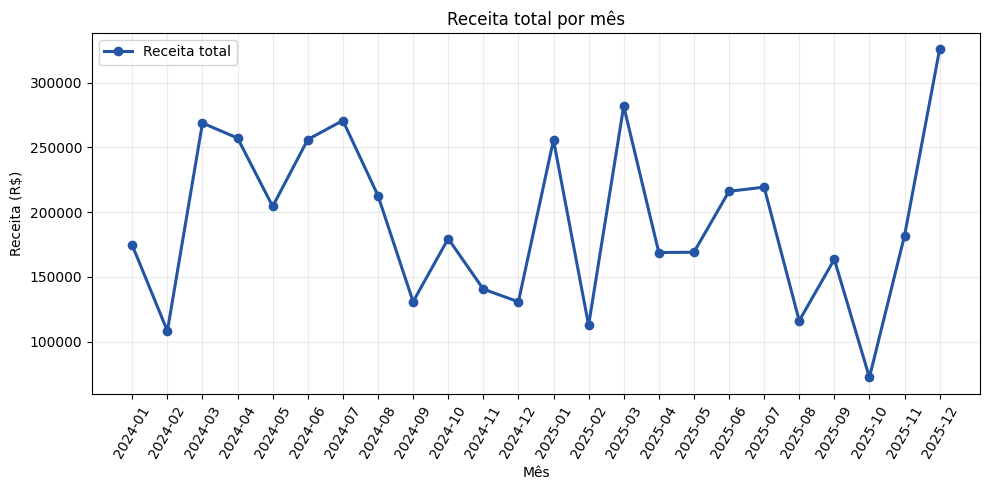

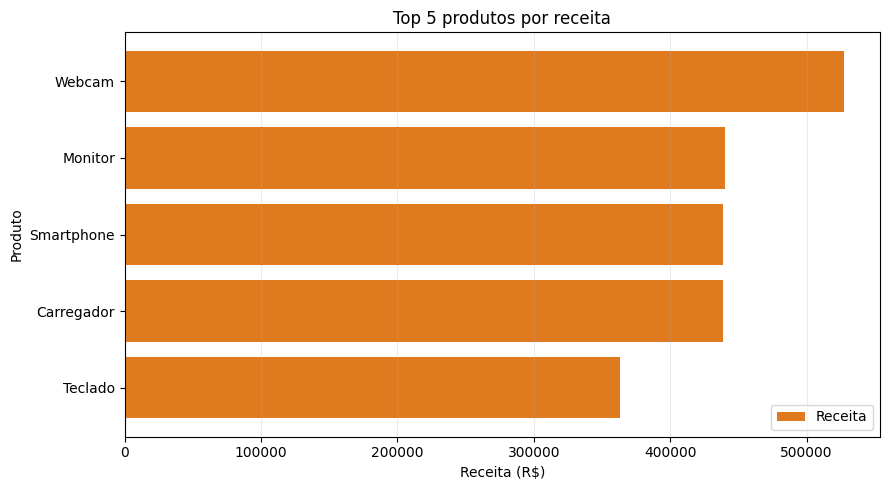

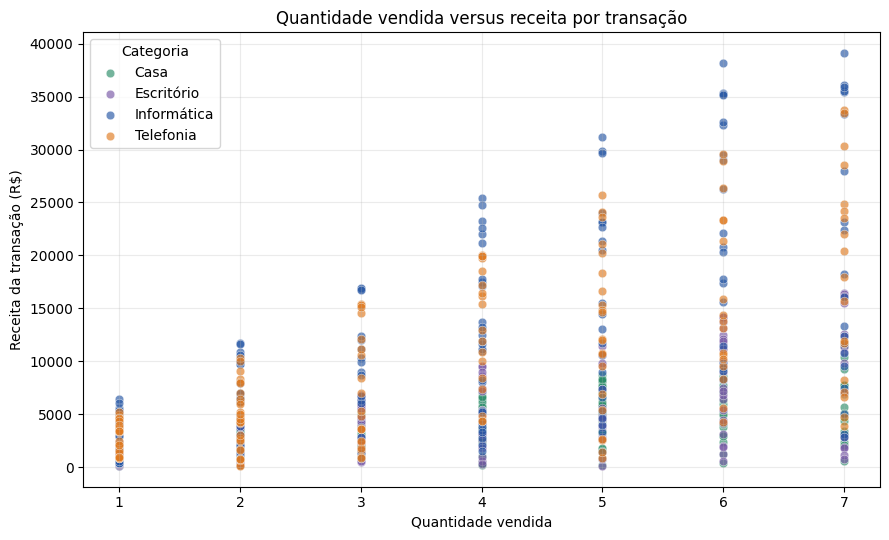

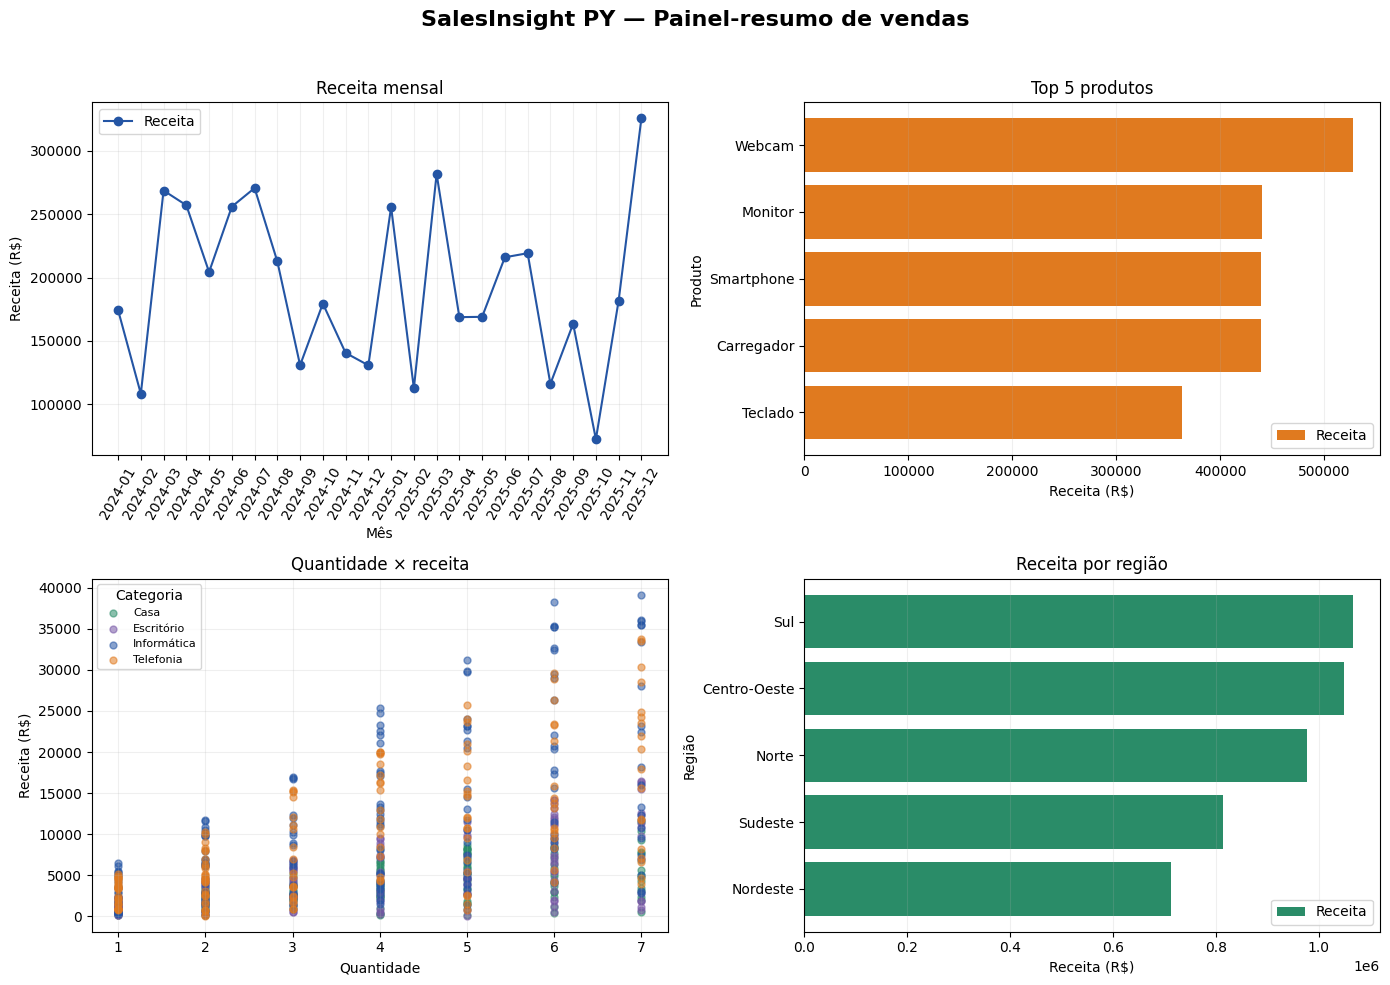

Gráficos exportados:
- saidas/receita_por_mes.png
- saidas/top_produtos.png
- saidas/quantidade_vs_receita.png
- saidas/painel_resumo.png


In [19]:
def gerar_graficos(df, metricas, pasta_saida=PASTA_SAIDA):
    """Gera e salva as quatro figuras solicitadas em formato PNG."""
    pasta_saida = Path(pasta_saida)
    pasta_saida.mkdir(parents=True, exist_ok=True)

    mensal = metricas["por_mes"]
    produtos = metricas["top_produtos"]
    regioes = metricas["por_regiao"]

    # Figura 1: linha de receita mensal.
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(mensal["periodo"], mensal["receita_total"], marker="o",
            linewidth=2.2, color=CORES["azul"], label="Receita total")
    ax.set_title("Receita total por mês")
    ax.set_xlabel("Mês")
    ax.set_ylabel("Receita (R$)")
    ax.legend()
    ax.tick_params(axis="x", rotation=60)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(pasta_saida / "receita_por_mes.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Figura 2: Top 5 produtos.
    fig, ax = plt.subplots(figsize=(9, 5))
    barras = produtos.sort_values("receita_total", ascending=True)
    ax.barh(barras["produto"], barras["receita_total"], color=CORES["laranja"], label="Receita")
    ax.set_title("Top 5 produtos por receita")
    ax.set_xlabel("Receita (R$)")
    ax.set_ylabel("Produto")
    ax.legend()
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(pasta_saida / "top_produtos.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Figura 3: dispersão quantidade x receita, com cor por categoria.
    fig, ax = plt.subplots(figsize=(9, 5.5))
    paleta_categorias = {
        "Informática": CORES["azul"],
        "Telefonia": CORES["laranja"],
        "Casa": CORES["verde"],
        "Escritório": CORES["roxo"],
    }
    for categoria, grupo in df.groupby("categoria"):
        ax.scatter(grupo["quantidade"], grupo["receita_total"],
                   alpha=0.65, s=38, label=categoria,
                   color=paleta_categorias.get(categoria, CORES["cinza"]),
                   edgecolors="white", linewidths=0.4)
    ax.set_title("Quantidade vendida versus receita por transação")
    ax.set_xlabel("Quantidade vendida")
    ax.set_ylabel("Receita da transação (R$)")
    ax.legend(title="Categoria")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(pasta_saida / "quantidade_vs_receita.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Figura 4: painel 2x2 com título geral.
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    ax1, ax2 = axes[0, 0], axes[0, 1]
    ax3, ax4 = axes[1, 0], axes[1, 1]

    ax1.plot(mensal["periodo"], mensal["receita_total"], marker="o",
             color=CORES["azul"], label="Receita")
    ax1.set_title("Receita mensal")
    ax1.set_xlabel("Mês")
    ax1.set_ylabel("Receita (R$)")
    ax1.tick_params(axis="x", rotation=60)
    ax1.legend()
    ax1.grid(alpha=0.2)

    barras = produtos.sort_values("receita_total", ascending=True)
    ax2.barh(barras["produto"], barras["receita_total"], color=CORES["laranja"], label="Receita")
    ax2.set_title("Top 5 produtos")
    ax2.set_xlabel("Receita (R$)")
    ax2.set_ylabel("Produto")
    ax2.legend()
    ax2.grid(axis="x", alpha=0.2)

    for categoria, grupo in df.groupby("categoria"):
        ax3.scatter(grupo["quantidade"], grupo["receita_total"], alpha=0.55, s=25,
                    label=categoria, color=paleta_categorias.get(categoria, CORES["cinza"]))
    ax3.set_title("Quantidade × receita")
    ax3.set_xlabel("Quantidade")
    ax3.set_ylabel("Receita (R$)")
    ax3.legend(title="Categoria", fontsize=8)
    ax3.grid(alpha=0.2)

    barras_regiao = regioes.sort_values("receita_total", ascending=True)
    ax4.barh(barras_regiao["regiao"], barras_regiao["receita_total"],
             color=CORES["verde"], label="Receita")
    ax4.set_title("Receita por região")
    ax4.set_xlabel("Receita (R$)")
    ax4.set_ylabel("Região")
    ax4.legend()
    ax4.grid(axis="x", alpha=0.2)

    fig.suptitle("SalesInsight PY — Painel-resumo de vendas", fontsize=16, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(pasta_saida / "painel_resumo.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    arquivos = [
        "receita_por_mes.png", "top_produtos.png",
        "quantidade_vs_receita.png", "painel_resumo.png"
    ]
    print("Gráficos exportados:")
    for nome in arquivos:
        print("-", pasta_saida / nome)

gerar_graficos(df, metricas)

## RF08 — Funções reutilizáveis, classe e função de ordem superior

O fluxo está organizado em funções com parâmetros, retornos e docstrings. Para atender também ao requisito de classe, a classe SalesInsight reúne as etapas principais. A função aplicar_funcao_coluna recebe outra função como argumento e a aplica a uma coluna — exemplo de função de ordem superior.

A classe reutiliza as funções já definidas, evitando duplicação de lógica.

In [20]:
def aplicar_funcao_coluna(df, coluna, funcao, nova_coluna=None):
    """Aplica uma função recebida como argumento a uma coluna do DataFrame.

    """
    resultado = df.copy()
    destino = nova_coluna or coluna
    resultado[destino] = resultado[coluna].apply(funcao)
    return resultado

# Demonstração da função de ordem superior: recebe str.title como função.
df_exemplo_funcao = aplicar_funcao_coluna(df, "regiao", lambda valor: valor.title(), "regiao_formatada")
display(df_exemplo_funcao[["regiao", "regiao_formatada"]].head())


class SalesInsight:
    """Coordena o pipeline completo de análise de vendas."""

    def __init__(self, caminho_csv="vendas.csv", pasta_saida="saidas"):
        self.caminho_csv = Path(caminho_csv)
        self.pasta_saida = Path(pasta_saida)
        self.pasta_saida.mkdir(parents=True, exist_ok=True)
        self.df_bruto = None
        self.df_limpo = None
        self.df = None
        self.metricas = None
        self.clientes = None
        self.relatorio_limpeza = None

    def executar(self):
        """Executa criação/leitura, inspeção, limpeza e análise na ordem correta."""
        criar_dataset_sintetico(self.caminho_csv)
        self.df_bruto = pd.read_csv(self.caminho_csv)
        inspecionar_dados(self.df_bruto)
        self.df_limpo, self.relatorio_limpeza = limpar_dados(self.df_bruto)
        self.df = adicionar_colunas_derivadas(self.df_limpo)
        self.metricas = calcular_metricas(self.df)
        self.clientes = segmentar_clientes(self.df)
        gerar_graficos(self.df, self.metricas, self.pasta_saida)
        exportar_resultados(
            self.metricas, self.clientes, self.df, self.relatorio_limpeza,
            self.pasta_saida
        )
        return self

,regiao,regiao_formatada
0,Centro-Oeste,Centro-Oeste
1,Norte,Norte
2,Norte,Norte
3,Nordeste,Nordeste
4,Sul,Sul


## RF09 — Exportar resultados em CSV e JSON

É exportada:
- métricas mensais para CSV;
- segmentação dos clientes para CSV;
- estatísticas gerais para JSON usando json.dump();
- leitura do JSON com json.load() para comprovar a gravação.

Os arquivos são salvos na pasta saidas/.

In [21]:
def exportar_resultados(metricas, clientes, df, relatorio_limpeza, pasta_saida=PASTA_SAIDA):
    """Exporta tabelas CSV e estatísticas JSON, e lê o JSON de volta."""
    pasta_saida = Path(pasta_saida)
    pasta_saida.mkdir(parents=True, exist_ok=True)

    metricas["por_mes"].to_csv(pasta_saida / "metricas_por_mes.csv", index=False, encoding="utf-8-sig")
    clientes.to_csv(pasta_saida / "segmentacao_clientes.csv", index=False, encoding="utf-8-sig")
    metricas["top_produtos"].to_csv(pasta_saida / "top_produtos.csv", index=False, encoding="utf-8-sig")
    metricas["por_categoria"].to_csv(pasta_saida / "receita_por_categoria.csv", index=False, encoding="utf-8-sig")
    metricas["por_regiao"].to_csv(pasta_saida / "receita_por_regiao.csv", index=False, encoding="utf-8-sig")

    estatisticas = {
        "total_registros_analisados": int(len(df)),
        "receita_total": round(float(df["receita_total"].sum()), 2),
        "quantidade_total_vendida": int(df["quantidade"].sum()),
        "ticket_medio_geral": round(float(df["receita_total"].sum() / len(df)), 2) if len(df) else 0,
        "data_inicial": str(df["data_venda"].min().date()) if len(df) else None,
        "data_final": str(df["data_venda"].max().date()) if len(df) else None,
        "clientes_unicos": int(df["cliente"].nunique()),
        "produtos_unicos": int(df["produto"].nunique()),
        "relatorio_limpeza": relatorio_limpeza,
        "receita_por_categoria": {
            str(linha["categoria"]): round(float(linha["receita_total"]), 2)
            for _, linha in metricas["por_categoria"].iterrows()
        },
        "receita_por_regiao": {
            str(linha["regiao"]): round(float(linha["receita_total"]), 2)
            for _, linha in metricas["por_regiao"].iterrows()
        },
    }

    caminho_json = pasta_saida / "estatisticas_gerais.json"
    with open(caminho_json, "w", encoding="utf-8") as arquivo:
        json.dump(estatisticas, arquivo, ensure_ascii=False, indent=4)

    # Lê de volta o JSON gravado para comprovar a operação.
    with open(caminho_json, "r", encoding="utf-8") as arquivo:
        estatisticas_lidas = json.load(arquivo)

    print("Arquivos CSV e JSON exportados para:", pasta_saida.resolve())
    print("\nConteúdo do JSON lido de volta:")
    print(json.dumps(estatisticas_lidas, ensure_ascii=False, indent=2))
    return estatisticas_lidas

## RF10 — Executar o fluxo completo (main)

A função main() executa todas as etapas de ponta a ponta. A ordem respeita o enunciado: primeiro leitura e inspeção, depois limpeza, depois colunas derivadas, agregações, segmentação, gráficos e exportações.

No notebook, chamamos main() explicitamente. No arquivo Python equivalente, o bloco if __name__ == "__main__": permite executar o programa pelo terminal.

Dataset existente encontrado: /content/vendas.csv
Dimensões (linhas, colunas): (600, 8)

Colunas:
['id_venda', 'data_venda', 'produto', 'categoria', 'regiao', 'cliente', 'quantidade', 'preco_unitario']

Tipos de dados:
id_venda            int64
data_venda         object
produto            object
categoria          object
regiao             object
cliente            object
quantidade          int64
preco_unitario    float64
dtype: object

Valores nulos por coluna:
id_venda          0
data_venda        0
produto           0
categoria         0
regiao            0
cliente           0
quantidade        0
preco_unitario    0
dtype: int64

Primeiros registros:


,id_venda,data_venda,produto,categoria,regiao,cliente,quantidade,preco_unitario
0,1,2025-07-19,Monitor,Informática,Centro-Oeste,Cliente_069,1,2897.60
1,2,2025-01-19,Aspirador,Casa,Norte,Cliente_059,6,201.22
2,3,2025-07-28,Ventilador,Casa,Norte,Cliente_037,4,261.12
3,4,2025-07-25,Fone Bluetooth,Telefonia,Nordeste,Cliente_033,6,4822.11
4,5,2024-11-20,Cafeteira,Casa,Sul,Cliente_045,7,436.08


RELATÓRIO DE LIMPEZA
- Registros entrada: 600
- Textos padronizados: 2
- Datas invalidas removidas: 1
- Quantidades invalidas removidas: 0
- Precos invalidos removidos: 0
- Registros finais: 599
- Registros removidos total: 1
- Registros sem remocao: 599


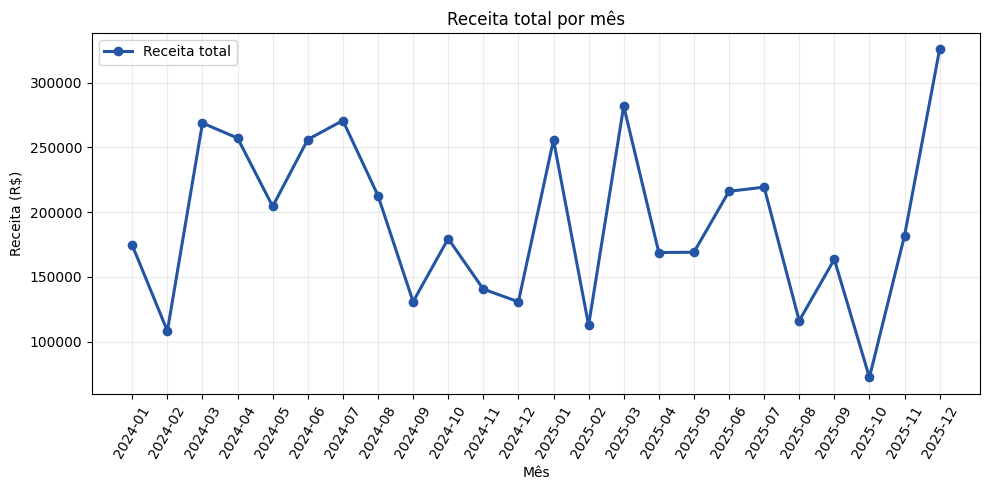

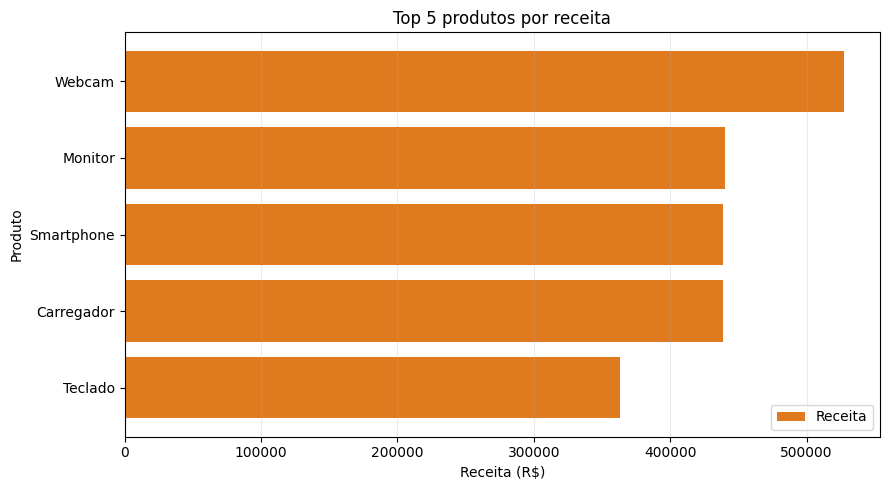

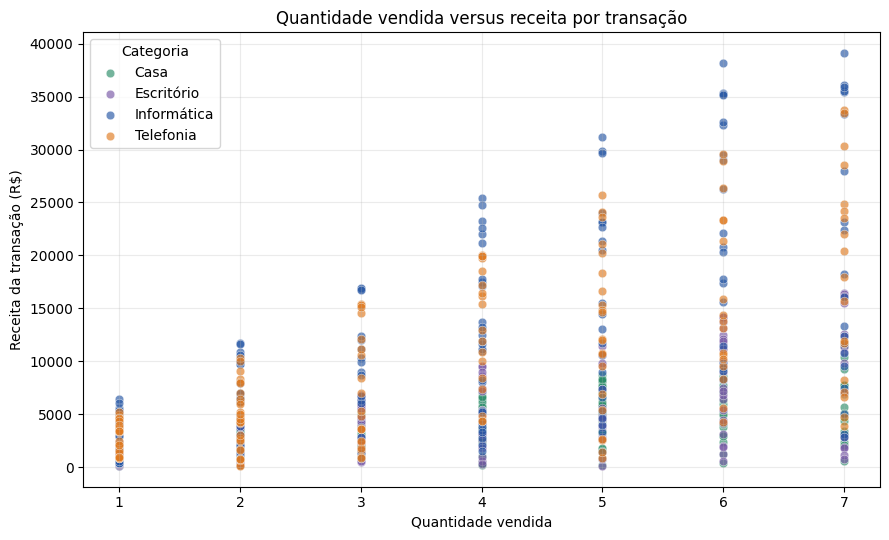

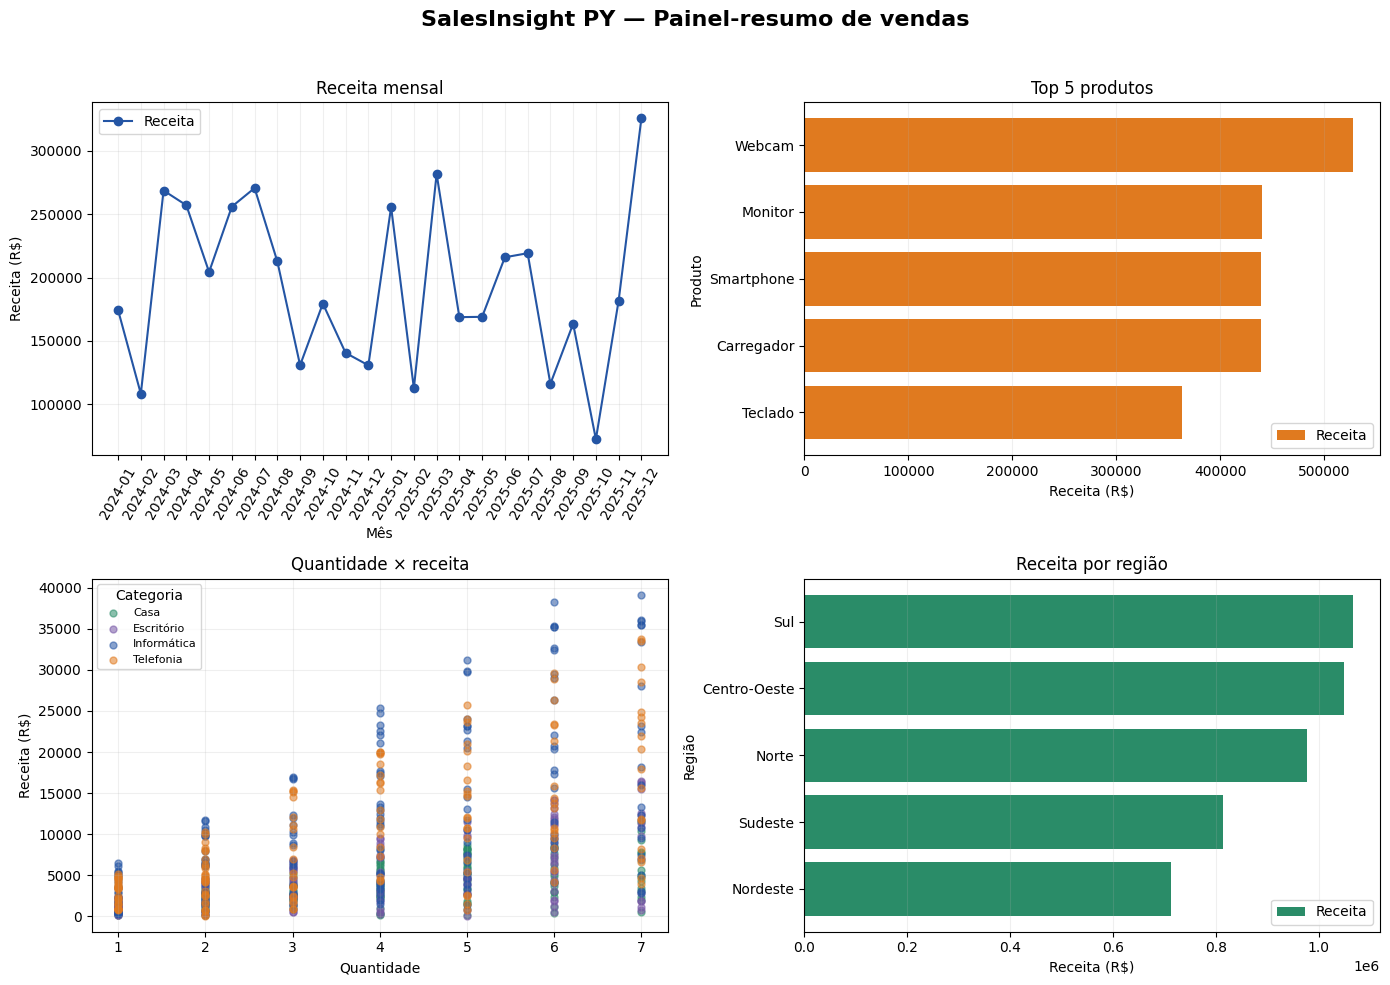

Gráficos exportados:
- saidas/receita_por_mes.png
- saidas/top_produtos.png
- saidas/quantidade_vs_receita.png
- saidas/painel_resumo.png
Arquivos CSV e JSON exportados para: /content/saidas

Conteúdo do JSON lido de volta:
{
  "total_registros_analisados": 599,
  "receita_total": 4617637.97,
  "quantidade_total_vendida": 2298,
  "ticket_medio_geral": 7708.91,
  "data_inicial": "2024-01-04",
  "data_final": "2025-12-31",
  "clientes_unicos": 80,
  "produtos_unicos": 17,
  "relatorio_limpeza": {
    "registros_entrada": 600,
    "textos_padronizados": 2,
    "datas_invalidas_removidas": 1,
    "quantidades_invalidas_removidas": 0,
    "precos_invalidos_removidos": 0,
    "registros_finais": 599,
    "registros_removidos_total": 1,
    "registros_sem_remocao": 599
  },
  "receita_por_categoria": {
    "Informática": 1940263.18,
    "Telefonia": 1464245.04,
    "Escritório": 691377.02,
    "Casa": 521752.73
  },
  "receita_por_regiao": {
    "Sul": 1066145.53,
    "Centro-Oeste": 1048655.

,categoria,receita_total,quantidade
2,Informática,1940263.18,628



Região com maior receita:


,regiao,receita_total,quantidade,n_vendas,ticket_medio
4,Sul,1066145.53,493,137,7782.084161



Clientes por segmento:


,n_clientes
segmento,
Ouro,77
Prata,3


In [22]:
def main():
    """Executa o pipeline completo SalesInsight PY e retorna o objeto da análise."""
    analise = SalesInsight(caminho_csv="vendas.csv", pasta_saida=PASTA_SAIDA)
    analise.executar()

    print("\n=== RESUMO EXECUTIVO ===")
    print(f"Registros analisados: {len(analise.df):,}")
    print(f"Receita total: R$ {analise.df['receita_total'].sum():,.2f}")
    print(f"Quantidade vendida: {analise.df['quantidade'].sum():,}")
    print(f"Clientes únicos: {analise.df['cliente'].nunique():,}")
    print("\nCategoria com maior receita:")
    display(analise.metricas["por_categoria"].head(1))
    print("\nRegião com maior receita:")
    display(analise.metricas["por_regiao"].head(1))
    print("\nClientes por segmento:")
    display(analise.clientes["segmento"].value_counts().rename_axis("segmento").to_frame("n_clientes"))
    return analise

# Execute esta célula para rodar o pipeline completo.
analise_final = main()